# Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

C:\Users\thala\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


# Loading dataset

In [2]:
df = pd.read_csv(r"C:\Users\thala\OneDrive\Documents\EDA project Innomatics\archive\train.csv")
df.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969


# Shape

In [3]:
df.shape   # We Have 550068 Rows and 12 Columns 

(550068, 12)

In [4]:
df.info()  # In Product Categories 2 and 3 the Non Null Value count is diiferent So we need to find it the null values 

<class 'pandas.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     550068 non-null  int64  
 1   Product_ID                  550068 non-null  str    
 2   Gender                      550068 non-null  str    
 3   Age                         550068 non-null  str    
 4   Occupation                  550068 non-null  int64  
 5   City_Category               550068 non-null  str    
 6   Stay_In_Current_City_Years  550068 non-null  str    
 7   Marital_Status              550068 non-null  int64  
 8   Product_Category_1          550068 non-null  int64  
 9   Product_Category_2          376430 non-null  float64
 10  Product_Category_3          166821 non-null  float64
 11  Purchase                    550068 non-null  int64  
dtypes: float64(2), int64(5), str(5)
memory usage: 59.3 MB


In [25]:
df.head(1)

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370


In [10]:
df.isnull().sum()      # FInding the Count of Missing Values

User_ID                            0
Product_ID                         0
Gender                             0
Age                                0
Occupation                         0
City_Category                      0
Stay_In_Current_City_Years         0
Marital_Status                     0
Product_Category_1                 0
Product_Category_2            173638
Product_Category_3            383247
Purchase                           0
dtype: int64

In [11]:
(df.isnull().mean() * 100).round(2)

User_ID                        0.00
Product_ID                     0.00
Gender                         0.00
Age                            0.00
Occupation                     0.00
City_Category                  0.00
Stay_In_Current_City_Years     0.00
Marital_Status                 0.00
Product_Category_1             0.00
Product_Category_2            31.57
Product_Category_3            69.67
Purchase                       0.00
dtype: float64

In [12]:
df.duplicated().sum()  #Checking Dplicates Values - here We DontHave any Duplicated values

np.int64(0)

# Data Conversion

In [27]:
df["User_ID"] = df["User_ID"].astype("string")

categorical_cols = [
    "Gender",
    "Age",
    "Occupation",
    "City_Category",
    "Stay_In_Current_City_Years",
    "Marital_Status",
    "Product_Category_1",
    "Product_Category_2",
    "Product_Category_3"
]
for col in categorical_cols:
    df[col] = df[col].astype("category")

In [28]:
# Verifying
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype   
---  ------                      --------------   -----   
 0   User_ID                     550068 non-null  string  
 1   Product_ID                  550068 non-null  str     
 2   Gender                      550068 non-null  category
 3   Age                         550068 non-null  category
 4   Occupation                  550068 non-null  category
 5   City_Category               550068 non-null  category
 6   Stay_In_Current_City_Years  550068 non-null  category
 7   Marital_Status              550068 non-null  category
 8   Product_Category_1          550068 non-null  category
 9   Product_Category_2          376430 non-null  category
 10  Product_Category_3          166821 non-null  category
 11  Purchase                    550068 non-null  int64   
dtypes: category(9), int64(1), str(1), string(1)
memory usage: 25.7 MB


In [30]:
df.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969


# Filling Missing values 

In [31]:
df["Product_Category_2"] = (df["Product_Category_2"].cat.add_categories([0]).fillna(0))
df["Product_Category_3"] = (df["Product_Category_3"].cat.add_categories([0]).fillna(0))

# Handling Missing Product Categories
Missing values in `Product_Category_2` and `Product_Category_3`
were replaced with 0 to represent the absence of a recorded
secondary or tertiary product category.

Here, 0 is a placeholder for missing information and does not
represent an actual product category. This distinction should
be considered when interpreting category counts and visualizations.

In [32]:
df.isna().sum()

User_ID                       0
Product_ID                    0
Gender                        0
Age                           0
Occupation                    0
City_Category                 0
Stay_In_Current_City_Years    0
Marital_Status                0
Product_Category_1            0
Product_Category_2            0
Product_Category_3            0
Purchase                      0
dtype: int64

# Univariate analysis

In [33]:
df["Purchase"].describe()

count    550068.000000
mean       9263.968713
std        5023.065394
min          12.000000
25%        5823.000000
50%        8047.000000
75%       12054.000000
max       23961.000000
Name: Purchase, dtype: float64

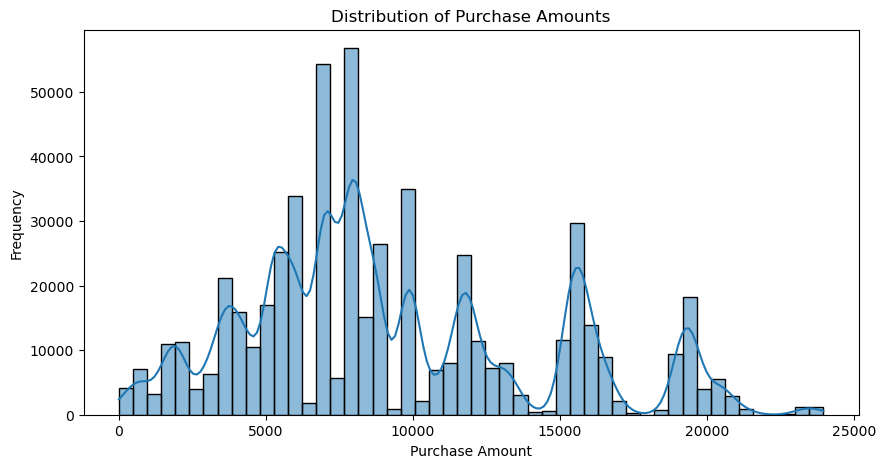

In [34]:
# Histogram - Understand the distribution
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="Purchase", bins=50, kde=True)
plt.title("Distribution of Purchase Amounts")
plt.xlabel("Purchase Amount")
plt.ylabel("Frequency")
plt.show()

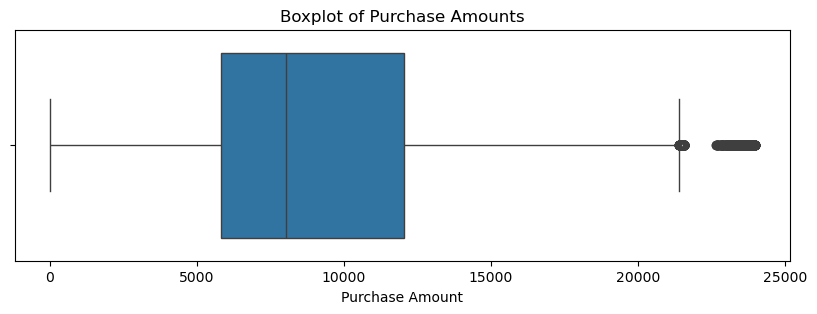

In [35]:
# Boxplot -Understand spread and potential outliers
plt.figure(figsize=(10, 3))
sns.boxplot(x=df["Purchase"])
plt.title("Boxplot of Purchase Amounts")
plt.xlabel("Purchase Amount")
plt.show()

#  Univariate Analysis — Purchase Amount

A histogram was used to understand the distribution of transaction purchase amounts, while a boxplot was used to examine the median, spread, and potential outliers.

The boxplot identified purchase amounts above the upper IQR threshold as potential outliers. These observations were investigated rather than automatically removed because unusually high transactions may represent genuine customer purchases.

Valid observations were retained to preserve the original transaction information. The IQR method and the number of flagged observations were documented as part of the data analysis.

In [36]:
print(df["Gender"].value_counts())
print(df["Age"].value_counts())
print(df["City_Category"].value_counts())

Gender
M    414259
F    135809
Name: count, dtype: int64
Age
26-35    219587
36-45    110013
18-25     99660
46-50     45701
51-55     38501
55+       21504
0-17      15102
Name: count, dtype: int64
City_Category
B    231173
C    171175
A    147720
Name: count, dtype: int64


In [37]:
Q1 = df["Purchase"].quantile(0.25)
Q3 = df["Purchase"].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
outliers = df[
    (df["Purchase"] < lower_limit) |
    (df["Purchase"] > upper_limit)]
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of outliers:", len(outliers))
print("Percentage of outliers:", round(len(outliers) / len(df) * 100, 2), "%")

Q1: 5823.0
Q3: 12054.0
IQR: 6231.0
Lower limit: -3523.5
Upper limit: 21400.5
Number of outliers: 2677
Percentage of outliers: 0.49 %


# Outlier Detection and Treatment — Purchase

The Interquartile Range (IQR) method was used to detect potential outliers in the `Purchase` column. The first quartile (Q1) was 5,823, and the third quartile (Q3) was 12,054, resulting in an IQR of 6,231.

The calculated upper threshold was 21,400.5, while the lower threshold was −3,523.5. A total of 2,677 observations (approximately 0.49% of all transactions) were identified as potential outliers.

Since unusually high purchase amounts may represent legitimate customer transactions, these observations were not automatically removed. They were retained pending validation to preserve the integrity of the original dataset.

Gender
M    414259
F    135809
Name: count, dtype: int64
Gender
M    75.31
F    24.69
Name: proportion, dtype: float64


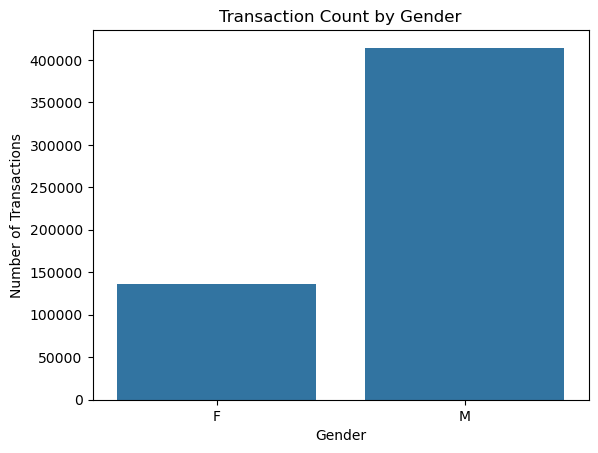

In [38]:
print(df["Gender"].value_counts())
print(df["Gender"].value_counts(normalize=True).mul(100).round(2))

sns.countplot(data=df, x="Gender")
plt.title("Transaction Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")
plt.show()

###  Gender Distribution

The count plot shows the number of purchase transactions
recorded for each gender. The taller bar represents the
gender with more transactions in the dataset.

This describes transaction frequency, not necessarily
the number of unique customers or their average spending.

# Bi-Variate Analysis
Bivariate analysis examines the relationship between two variables.
The objective is to understand how purchase amounts vary across
customer groups and product categories.

Q1. Does the average purchase amount differ between male and female customers?


In [40]:
gender_purchase = df.groupby("Gender", observed=True)["Purchase"].mean()
print(gender_purchase)

Gender
F    8734.565765
M    9437.526040
Name: Purchase, dtype: float64


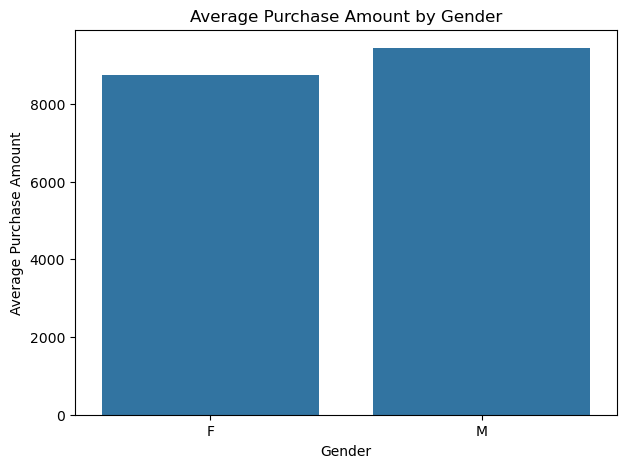

In [41]:
# Visualiozationh
plt.figure(figsize=(7, 5))
sns.barplot(data=df,x="Gender",y="Purchase",errorbar=None)
plt.title("Average Purchase Amount by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Purchase Amount")
plt.show()

Q2. Which gender contributes the highest total purchase amount?

In [42]:
gender_total = df.groupby("Gender", observed=True)["Purchase"].sum()
print(gender_total)

Gender
F    1186232642
M    3909580100
Name: Purchase, dtype: int64


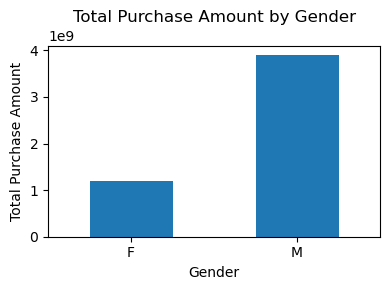

In [95]:
gender_total.plot(kind='bar', figsize=(4, 3))
plt.title('Total Purchase Amount by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Purchase Amount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

-The chart compares the total purchase amount contributed
by each gender across all recorded transactions.

-The taller bar indicates the group contributing the
larger total purchase amount. This can be influenced by
the number of transactions as well as purchase values.

Q3. Which age group has the highest average purchase amount?

In [43]:
age_order = ["0-17", "18-25", "26-35","36-45", "46-50", "51-55", "55+"]
age_purchase = df.groupby("Age", observed=True)["Purchase"].mean().reindex(age_order)
print(age_purchase)

Age
0-17     8933.464640
18-25    9169.663606
26-35    9252.690633
36-45    9331.350695
46-50    9208.625697
51-55    9534.808031
55+      9336.280459
Name: Purchase, dtype: float64


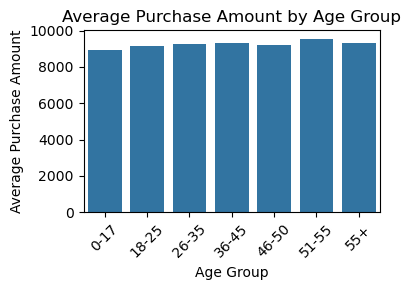

In [45]:
plt.figure(figsize=(4, 3))
sns.barplot(data=df,x="Age",y="Purchase",order=age_order,errorbar=None)
plt.title("Average Purchase Amount by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Purchase Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Q4. Which primary product category has the highest average purchase amount?

In [54]:
category_purchase = df.groupby("Product_Category_1", observed=True)["Purchase"].mean().sort_values(ascending=False)
print(category_purchase)

Product_Category_1
10    19675.570927
7     16365.689600
6     15838.478550
9     15537.375610
15    14780.451828
16    14766.037037
1     13606.218596
14    13141.625739
2     11251.935384
17    10170.759516
3     10096.705734
8      7498.958078
5      6240.088178
11     4685.268456
18     2972.864320
4      2329.659491
12     1350.859894
13      722.400613
20      370.481176
19       37.041797
Name: Purchase, dtype: float64


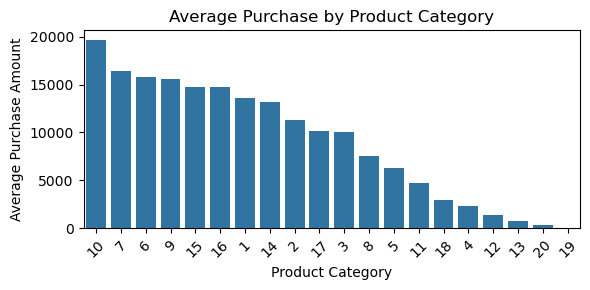

In [56]:
plt.figure(figsize=(6, 3))
sns.barplot(x=category_purchase.index.astype(str),y=category_purchase.values)
plt.title("Average Purchase by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Purchase Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Multivariate Analysis 
Objective:
Analyze the combined relationship between customer demographics,
product categories, and purchase amount to identify
customer spending patterns and business insights.

Does the relationship between age and purchase amount differ by gender?

In [61]:
age_gender_purchase = df.groupby( ['Age', 'Gender'], observed=True)['Purchase'].mean().reset_index()
age_gender_purchase

,Age,Gender,Purchase
0,0-17,F,8338.771985
1,0-17,M,9235.173670
2,18-25,F,8343.180201
3,18-25,M,9440.942971
4,26-35,F,8728.251754
5,26-35,M,9410.337578
6,36-45,F,8959.844056
7,36-45,M,9453.193643
8,46-50,F,8842.098947
9,46-50,M,9357.471509


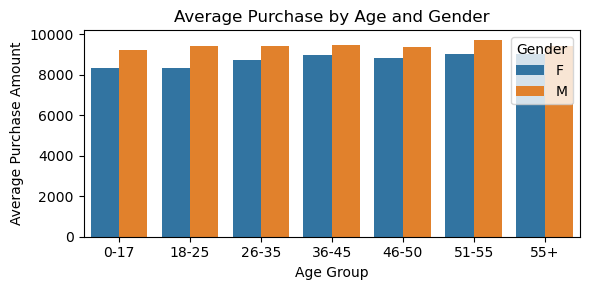

In [65]:
plt.figure(figsize=(6, 3))
sns.barplot(data=age_gender_purchase,x='Age',y='Purchase',hue='Gender')
plt.title('Average Purchase by Age and Gender')
plt.xlabel('Age Group')
plt.ylabel('Average Purchase Amount')
plt.tight_layout()
plt.show()

How do city category and gender together relate to purchase amount?

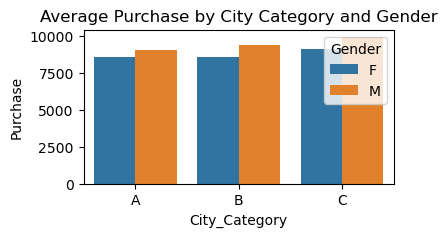

In [86]:
plt.figure(figsize=(4,2))
sns.barplot(data=df, x='City_Category', y='Purchase', hue='Gender', errorbar=None)
plt.title('Average Purchase by City Category and Gender')
plt.show()

How do age and city category together relate to purchase amount?

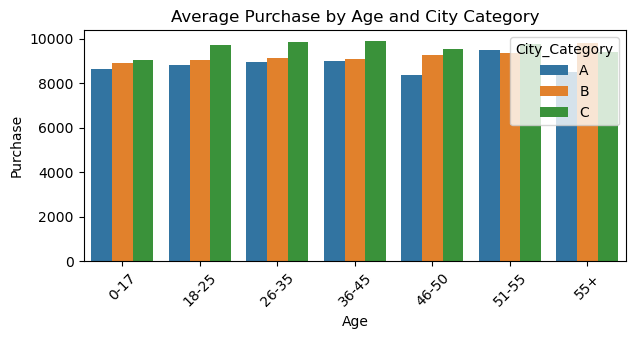

In [89]:
plt.figure(figsize=(7,3))
sns.barplot(data=df, x='Age', y='Purchase', hue='City_Category', errorbar=None)
plt.title('Average Purchase by Age and City Category')
plt.xticks(rotation=45)
plt.show()

How do gender and marital status together relate to purchase amount?

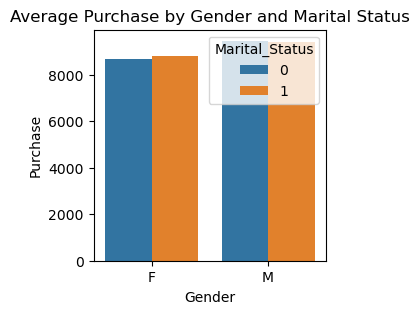

In [91]:
plt.figure(figsize=(3,3))
sns.barplot(data=df, x='Gender', y='Purchase', hue='Marital_Status', errorbar=None)
plt.title('Average Purchase by Gender and Marital Status')
plt.show()

# Pivot Table Analysis

Objective:
Summarize purchase behavior across customer demographics
and product categories using Pandas pivot tables.

How does average purchase amount vary by age group and gender?

In [92]:
pivot1 = pd.pivot_table(df,values='Purchase',index='Age',columns='Gender',aggfunc='mean')
pivot1.round(2)

Gender,F,M
Age,,
0-17,8338.77,9235.17
18-25,8343.18,9440.94
26-35,8728.25,9410.34
36-45,8959.84,9453.19
46-50,8842.10,9357.47
51-55,9042.45,9705.09
55+,9007.04,9438.20


- The pivot table compares the average purchase amount for males
  and females across different age groups.
- Rows represent age groups, and columns represent gender.
- Each value represents the average purchase amount for that
  particular age and gender combination.
- This analysis helps identify age groups with higher average
purchase amounts for different genders.

Which age groups and city categories have higher average purchases?

In [93]:
pivot2 = pd.pivot_table( df,values='Purchase',index='Age',columns='City_Category',aggfunc='mean')
pivot2.round(2)

City_Category,A,B,C
Age,,,
0-17,8615.11,8917.30,9059.50
18-25,8833.73,9031.71,9696.57
26-35,8952.50,9149.19,9835.39
36-45,8990.33,9107.90,9882.01
46-50,8348.53,9247.93,9533.18
51-55,9508.51,9340.91,9780.38
55+,8485.95,9803.56,9385.32



- The pivot table compares average purchase amounts across age
  groups and city categories.
- Rows represent age groups, and columns represent city categories.
- This analysis helps businesses compare customer spending
patterns across different age groups and city categories.